# Caso RapiMenú: ¿cuánto tardará el pedido?

**Curso:** Machine Learning para la Toma de Decisiones · Universidad del Pacífico
**Unidad:** Machine Learning II (supervisado · regresión)

---

## El caso

**Andrea Salazar** es gerenta de Operaciones de **RapiMenú**, una app de delivery que opera en 10 distritos de Lima. Cuando un cliente hace un pedido, la app le promete un tiempo de entrega calculado con una regla fija:

$$\text{tiempo prometido} = 30 \text{ min} + 3 \text{ min por km}$$

El directorio le pide **reducir a la mitad los pedidos que llegan más de 10 minutos tarde** (hoy, 1 de cada 3) **sin perder ventas** por prometer tiempos demasiado largos.

Dos gerencias no se ponen de acuerdo:

| Gerencia Comercial | Experiencia del Cliente |
|---|---|
| *"Prometamos tiempos cortos. Si la app dice 60 minutos, el cliente se va a otra app."* | *"Cada pedido tarde nos cuesta un cupón de S/ 6 y una queja. Prometamos tiempos más largos."* |

**El dilema:** el viernes Andrea debe llevar al comité una nueva forma de calcular el tiempo prometido. Su analista le comparte el historial de 12,000 pedidos de julio a setiembre de 2025.

## Preguntas del caso

Este notebook responde, en orden, las preguntas que Andrea necesita llevar al comité:

1. **¿Qué tenemos que predecir** para resolver la discusión entre ambas gerencias?
2. **¿Qué tan buena es la regla actual?** ¿Cuánto se equivoca, en minutos?
3. **¿Qué factores explican el tiempo de entrega?**
4. **¿Qué modelo predice mejor?** ¿Con qué métricas lo justificamos?
5. **¿En qué situaciones se equivoca más el modelo?**
6. **¿Qué tiempo debe prometer la app** para cumplir la meta del directorio? ¿Quién tenía razón: Comercial o Experiencia del Cliente?

## Datos

Archivo `RapiMenu_pedidos.csv`: 12,000 pedidos entre julio y setiembre de 2025. Los datos son simulados, pero reproducen el comportamiento típico de una operación de delivery.

| Variable | Nombre en el negocio | Descripción |
|---|---|---|
| `id_pedido`, `fecha_hora` | Identificador y fecha del pedido | No se usan como variables predictoras |
| `dia_semana`, `hora` | Momento del pedido | Día de la semana y hora |
| `distrito` | Distrito de entrega | 10 distritos de Lima |
| `tipo_restaurante` | Tipo de comida | Pollería, chifa, sushi, hamburguesas, etc. |
| `calificacion_restaurante` | Calificación del restaurante | Promedio de 1 a 5 |
| `n_productos` | Tamaño del pedido | Número de productos |
| `tiempo_prep_estimado` | Preparación declarada | Minutos que declara el restaurante |
| `distancia_km` | Distancia | Kilómetros entre el restaurante y el cliente |
| `vehiculo` | Vehículo del repartidor | Moto o bicicleta |
| `lluvia` | Lluvia | 1 si había lluvia o garúa intensa |
| `repartidores_disponibles` | Oferta de repartidores | Repartidores libres en la zona |
| `pedidos_activos_zona` | Demanda en la zona | Pedidos en curso en la zona |
| **`tiempo_entrega_min`** | **Tiempo de entrega** | **Variable objetivo: minutos desde el pedido hasta la entrega** |

## 1. Configuración

In [1]:
import os, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import xgboost as xgb
import lightgbm as lgb
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error, r2_score

warnings.filterwarnings("ignore")
SEED = 42
pd.set_option("display.float_format", "{:.2f}".format)
pd.set_option("display.max_colwidth", None)
AZUL, NARANJA, GRIS, MARINO = "#1570BC", "#E8892B", "#9AA8BF", "#000F5A"

### Parámetros del caso

Todo lo que depende del caso está en la celda siguiente. Para aplicar este análisis a otro problema de regresión, se modifica solo esta celda (y, si se desea, los gráficos exploratorios de la sección 4 y los ejemplos de la sección 10).

In [2]:
# Datos
ARCHIVO = "RapiMenu_pedidos.csv"
OBJETIVO = "tiempo_entrega_min"
UNIDAD = "min"
COLUMNAS_A_EXCLUIR = ["id_pedido", "fecha_hora"]                       # identificadores y fechas
CATEGORICAS = ["dia_semana", "distrito", "tipo_restaurante", "vehiculo"]

def crear_variables(data):
    # Variables derivadas del caso. Si no se necesitan, devolver data sin cambios.
    data = data.copy()
    data["fecha_hora"] = pd.to_datetime(data["fecha_hora"])
    data["mes"] = data["fecha_hora"].dt.month
    data["fin_de_semana"] = data["dia_semana"].isin(["Sábado", "Domingo"]).astype(int)
    data["hora_pico"] = data["hora"].isin([12, 13, 19, 20, 21]).astype(int)
    return data

# Línea base: cómo decide hoy el negocio, sin modelo
NOMBRE_LINEA_BASE = "Regla actual"
def linea_base(data):
    return 30 + 3 * data["distancia_km"]

# Indicador de negocio y meta
TOLERANCIA = 10                                   # error tolerado antes de que tenga costo
IND = f"% con retraso > {TOLERANCIA} {UNIDAD}"    # casos en que lo real supera la decisión por más de la tolerancia
META_RELATIVA = 0.5                               # meta: llevar el indicador al 50% del valor actual

# Valor económico del indicador
COSTO_POR_CASO = 6.0                              # S/ por pedido con más de 10 min de retraso (cupón)
NOMBRE_COSTO = "cupones"
CASOS_POR_MES = 4000                              # pedidos por mes (12,000 en tres meses)

In [3]:
df = pd.read_csv(ARCHIVO)
print(f"Pedidos: {len(df):,} | Variables: {df.shape[1]}")
df.head()

Pedidos: 12,000 | Variables: 15


,id_pedido,fecha_hora,dia_semana,hora,distrito,tipo_restaurante,calificacion_restaurante,n_productos,tiempo_prep_estimado,distancia_km,vehiculo,lluvia,repartidores_disponibles,pedidos_activos_zona,tiempo_entrega_min
0,100001,2025-07-01 10:16,Martes,10,Lince,Comida criolla,5.00,2,23,3.90,Moto,0,4,8,46
1,100002,2025-07-01 10:41,Martes,10,Barranco,Hamburguesas,4.10,3,17,3.70,Bicicleta,1,4,13,47
2,100003,2025-07-01 10:43,Martes,10,Barranco,Comida criolla,4.20,2,26,4.40,Moto,0,7,11,34
3,100004,2025-07-01 11:16,Martes,11,Surquillo,Comida criolla,4.40,3,25,2.90,Moto,0,4,7,41
4,100005,2025-07-01 11:17,Martes,11,Jesús María,Chifa,4.40,3,18,0.50,Moto,0,6,6,29


## 2. Revisión de calidad de los datos

Antes de explorar, revisamos tipos de datos, valores faltantes y duplicados.

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 15 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   id_pedido                 12000 non-null  int64  
 1   fecha_hora                12000 non-null  object 
 2   dia_semana                12000 non-null  object 
 3   hora                      12000 non-null  int64  
 4   distrito                  12000 non-null  object 
 5   tipo_restaurante          12000 non-null  object 
 6   calificacion_restaurante  12000 non-null  float64
 7   n_productos               12000 non-null  int64  
 8   tiempo_prep_estimado      12000 non-null  int64  
 9   distancia_km              12000 non-null  float64
 10  vehiculo                  12000 non-null  object 
 11  lluvia                    12000 non-null  int64  
 12  repartidores_disponibles  12000 non-null  int64  
 13  pedidos_activos_zona      12000 non-null  int64  
 14  tiempo

In [5]:
print("Valores faltantes por columna:")
print(df.isnull().sum())
print(f"\nPedidos duplicados: {df.duplicated().sum()}")

Valores faltantes por columna:
id_pedido                   0
fecha_hora                  0
dia_semana                  0
hora                        0
distrito                    0
tipo_restaurante            0
calificacion_restaurante    0
n_productos                 0
tiempo_prep_estimado        0
distancia_km                0
vehiculo                    0
lluvia                      0
repartidores_disponibles    0
pedidos_activos_zona        0
tiempo_entrega_min          0
dtype: int64

Pedidos duplicados: 0


In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
id_pedido,12000.00,106000.50,3464.25,100001.00,103000.75,106000.50,109000.25,112000.00
hora,12000.00,16.57,3.65,10.00,13.00,17.00,20.00,23.00
calificacion_restaurante,12000.00,4.40,0.29,3.20,4.20,4.40,4.60,5.00
n_productos,12000.00,2.59,1.25,1.00,2.00,2.00,3.00,10.00
tiempo_prep_estimado,12000.00,21.18,4.78,5.00,19.00,22.00,24.00,36.00
distancia_km,12000.00,3.09,2.24,0.30,1.50,2.50,4.10,14.00
lluvia,12000.00,0.12,0.32,0.00,0.00,0.00,0.00,1.00
repartidores_disponibles,12000.00,7.72,3.15,1.00,5.00,7.00,10.00,20.00
pedidos_activos_zona,12000.00,13.82,6.79,0.00,8.00,13.00,19.00,47.00
tiempo_entrega_min,12000.00,44.93,16.24,9.00,34.00,42.00,52.00,191.00


> **Opcional:** un reporte automático de exploración con `ydata-profiling` (tarda 1–2 minutos).

In [ ]:
# !pip install -q ydata-profiling
# from ydata_profiling import ProfileReport
# ProfileReport(df, title="RapiMenú · pedidos", minimal=True)

## 3. Pregunta 1 · ¿Qué tenemos que predecir?

Comercial quiere promesas cortas y Experiencia del Cliente quiere promesas largas. Las dos posturas aplican **la misma promesa a todos los pedidos**. La discusión se resuelve si sabemos **cuánto tardará cada pedido en particular**: así podemos prometer poco cuando el pedido será rápido y más cuando será lento.

Por eso, la variable a predecir es **`tiempo_entrega_min`**, un número continuo: es un problema de **regresión**, no de clasificación.

In [7]:
df[OBJETIVO].describe()

,tiempo_entrega_min
count,12000.00
mean,44.93
std,16.24
min,9.00
25%,34.00
50%,42.00
75%,52.00
max,191.00


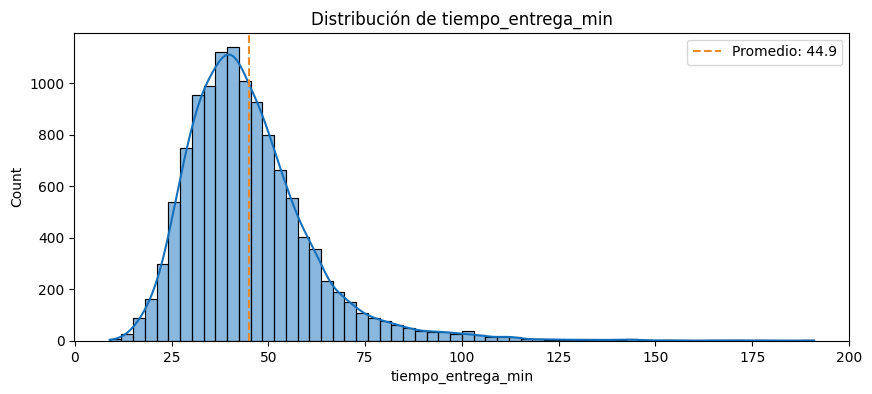

In [8]:
plt.figure(figsize=(10, 4))
sns.histplot(df[OBJETIVO], bins=60, kde=True, color=AZUL)
plt.axvline(df[OBJETIVO].mean(), color=NARANJA, ls="--", label=f"Promedio: {df[OBJETIVO].mean():.1f}")
plt.title(f"Distribución de {OBJETIVO}")
plt.xlabel(OBJETIVO)
plt.legend()
plt.show()

La distribución tiene una **cola larga a la derecha**: la mayoría de pedidos tarda entre 30 y 60 minutos, pero algunos tardan mucho más (restaurantes saturados, incidentes). Esos pedidos son los que generan cupones.

## 4. Pregunta 3 · ¿Qué factores explican el tiempo de entrega?

> **Al replicar:** estos gráficos son del caso RapiMenú. Cámbialos por las variables que creas que influyen en tu objetivo.

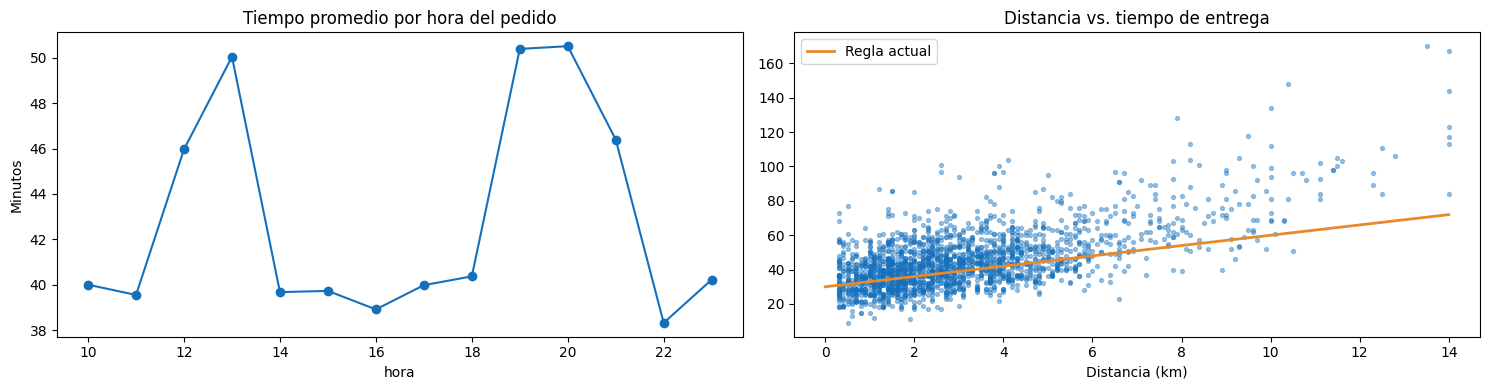

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
df.groupby("hora")["tiempo_entrega_min"].mean().plot(ax=axes[0], marker="o", color=AZUL)
axes[0].set_title("Tiempo promedio por hora del pedido")
axes[0].set_ylabel("Minutos")

muestra = df.sample(2000, random_state=SEED)
axes[1].scatter(muestra["distancia_km"], muestra["tiempo_entrega_min"], s=8, alpha=0.4, color=AZUL)
x = np.linspace(0, df["distancia_km"].max(), 50)
axes[1].plot(x, 30 + 3 * x, color=NARANJA, lw=2, label="Regla actual")
axes[1].set_title("Distancia vs. tiempo de entrega")
axes[1].set_xlabel("Distancia (km)")
axes[1].legend()
plt.tight_layout()
plt.show()

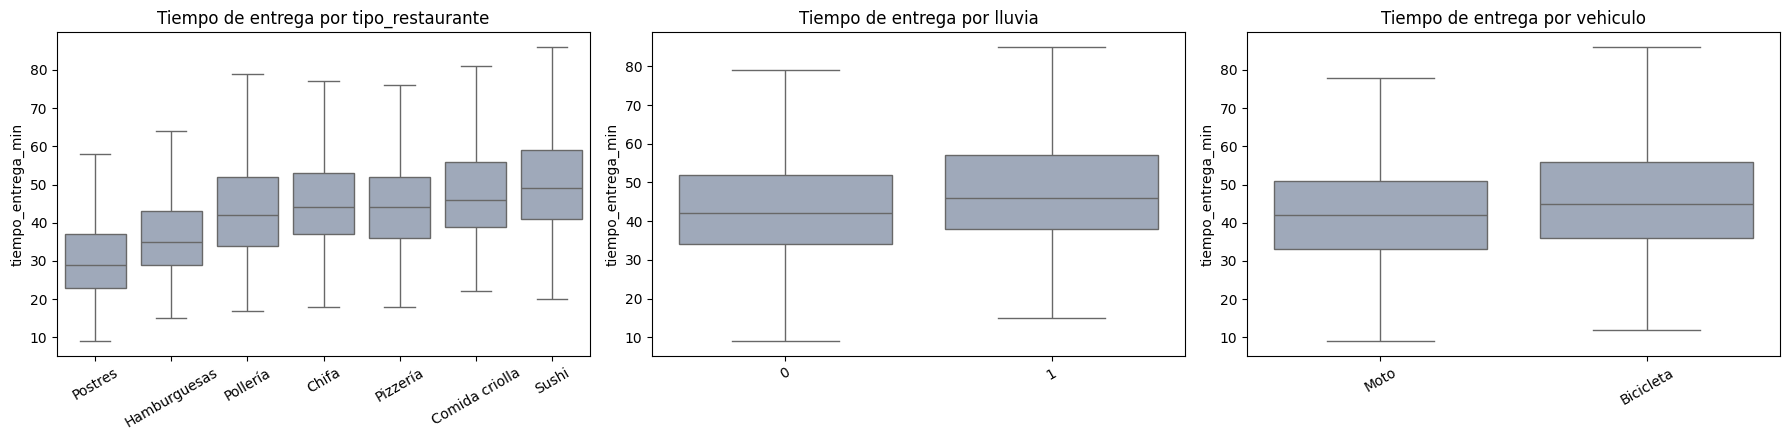

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, col in zip(axes, ["tipo_restaurante", "lluvia", "vehiculo"]):
    orden = df.groupby(col)["tiempo_entrega_min"].median().sort_values().index
    sns.boxplot(data=df, x=col, y="tiempo_entrega_min", order=orden, ax=ax, color=GRIS, showfliers=False)
    ax.set_title(f"Tiempo de entrega por {col}")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

In [11]:
por_distrito = df.groupby("distrito")["tiempo_entrega_min"].mean().reset_index()
fig = px.bar(por_distrito, x="distrito", y="tiempo_entrega_min",
             title="Tiempo promedio de entrega por distrito",
             labels={"tiempo_entrega_min": "Minutos", "distrito": "Distrito"},
             color_discrete_sequence=[AZUL])
fig.update_layout(xaxis={"categoryorder": "total descending"})
fig.show()

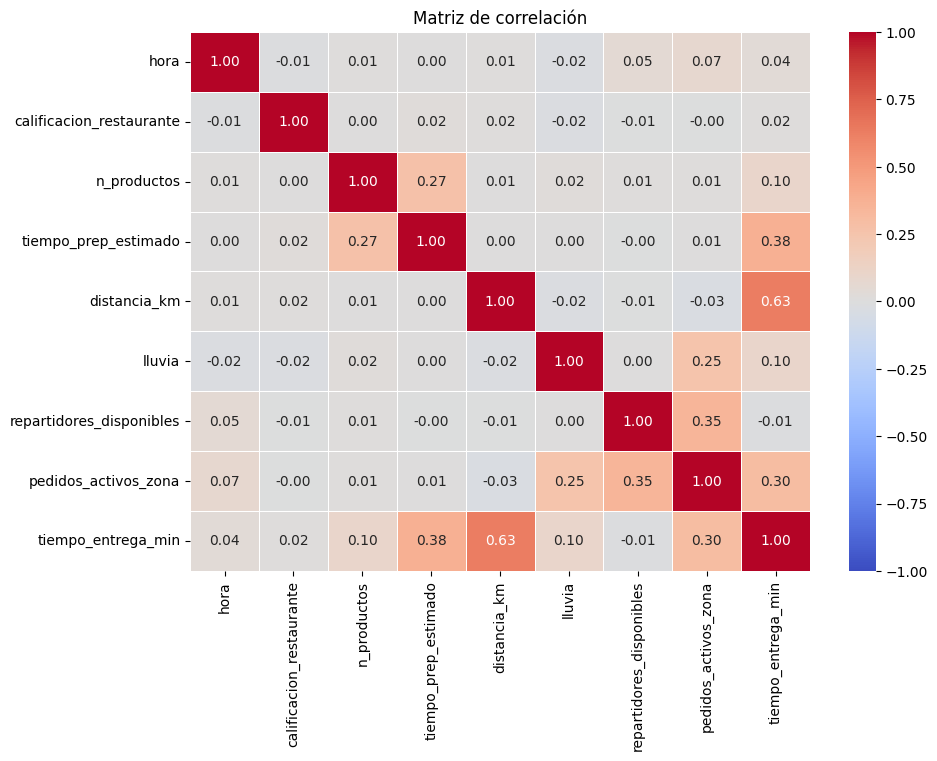

In [12]:
numericas = df.select_dtypes(include=np.number).drop(columns=["id_pedido"])
plt.figure(figsize=(10, 7))
sns.heatmap(numericas.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5)
plt.title("Matriz de correlación")
plt.show()

**Lectura:** el tiempo de entrega depende de la distancia, pero también de la **hora**, la **lluvia**, el **tipo de restaurante**, el **distrito**, el **vehículo** y la **oferta de repartidores**. La regla actual solo usa la distancia: ignora todo lo demás.

## 5. Preparación de los datos

- Se crean variables a partir de la fecha: **mes** y **fin de semana**, y una marca de **hora pico** (12–13 h y 19–21 h).
- Se eliminan `id_pedido` y `fecha_hora`: solo identifican el pedido y el modelo memorizaría casos, sin aprender patrones.
- Las variables categóricas se convierten en variables dummy (*one-hot encoding*).

In [13]:
datos = crear_variables(df)
y = datos[OBJETIVO]
X = datos.drop(columns=COLUMNAS_A_EXCLUIR + [OBJETIVO])
X = pd.get_dummies(X, columns=CATEGORICAS, drop_first=True, dtype=int)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=SEED)
print(f"Entrenamiento: {len(X_train):,} | Prueba: {len(X_test):,} | Variables: {X.shape[1]}")

Entrenamiento: 9,600 | Prueba: 2,400 | Variables: 33


## 6. Métricas

| Métrica | Nombre completo | Qué responde |
|---|---|---|
| **MAE** | *Mean Absolute Error* · error absoluto medio | ¿Cuántos minutos se equivoca en promedio? |
| **RMSE** | *Root Mean Squared Error* · raíz del error cuadrático medio | ¿Hay errores grandes? Los castiga más |
| **MAPE** | *Mean Absolute Percentage Error* · error porcentual absoluto medio | ¿Cuánto se equivoca en % del tiempo real? |
| **R²** | *Coefficient of Determination* · coeficiente de determinación | ¿Cuánto mejora frente a predecir siempre el promedio? |

Además, dos **métricas de negocio**:

- **% con retraso > 10 min:** pedidos que llegan más de 10 minutos después de lo prometido. Es la meta del directorio.
- **% con error > 10 min:** pedidos donde la predicción falla por más de 10 minutos, hacia arriba o hacia abajo.

In [14]:
def metricas(y_real, y_pred):
    error = y_real - y_pred
    return {"MAE": mean_absolute_error(y_real, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_real, y_pred)),
            "MAPE (%)": mean_absolute_percentage_error(y_real, y_pred) * 100,
            "R²": r2_score(y_real, y_pred),
            IND: (error > TOLERANCIA).mean() * 100,
            f"% con error > {TOLERANCIA} {UNIDAD}": (error.abs() > TOLERANCIA).mean() * 100}

## 7. Pregunta 2 · ¿Qué tan buena es la regla actual?

In [15]:
pred_regla = linea_base(datos.loc[X_test.index])
pd.Series(metricas(y_test, pred_regla), name=NOMBRE_LINEA_BASE).to_frame()

,Regla actual
MAE,10.59
RMSE,14.91
MAPE (%),22.53
R²,0.23
% con retraso > 10 min,30.75
% con error > 10 min,38.83


In [16]:
X_test.head(3)

,hora,calificacion_restaurante,n_productos,tiempo_prep_estimado,distancia_km,lluvia,repartidores_disponibles,pedidos_activos_zona,mes,fin_de_semana,...,distrito_San Isidro,distrito_Surco,distrito_Surquillo,tipo_restaurante_Comida criolla,tipo_restaurante_Hamburguesas,tipo_restaurante_Pizzería,tipo_restaurante_Pollería,tipo_restaurante_Postres,tipo_restaurante_Sushi,vehiculo_Moto
1935,20,4.40,1,24,2.90,0,10,12,7,0,...,0,1,0,1,0,0,0,0,0,1
6494,21,4.10,4,27,1.40,0,11,13,8,0,...,0,0,0,0,0,1,0,0,0,1
1720,20,4.10,3,29,0.40,0,11,12,7,0,...,0,1,0,0,0,0,0,0,1,1


In [18]:
retraso_regla = ((y_test - pred_regla) > TOLERANCIA).mean() * 100
META = retraso_regla * META_RELATIVA
print(f"Hoy, con la regla, el {retraso_regla:.1f}% de los pedidos llega con más de 10 minutos de retraso.")
print(f"Meta del directorio: reducirlo a la mitad, es decir, a {META:.1f}% o menos.")

Hoy, con la regla, el 30.8% de los pedidos llega con más de 10 minutos de retraso.
Meta del directorio: reducirlo a la mitad, es decir, a 15.4% o menos.


**Respuesta:** la regla se equivoca en promedio unos 10 minutos y cerca de un tercio de los pedidos llega con más de 10 minutos de retraso. Su R² es bajo: explica poco de la variación del tiempo de entrega. Esta es la **línea base** que cualquier modelo debe superar.

## 8. Pregunta 4 · ¿Qué modelo predice mejor?

Comparamos modelos de menor a mayor complejidad. Como en el ciclo anterior, el árbol de decisión se ajusta con **GridSearchCV** (búsqueda de hiperparámetros con validación cruzada).

In [19]:
param_grid = {"max_depth": [4, 6, 8, 10],
              "min_samples_leaf": [5, 20, 50],
              "max_features": [None, 0.5, 0.8]}
grid_arbol = GridSearchCV(DecisionTreeRegressor(random_state=SEED), param_grid,
                          cv=5, scoring="neg_root_mean_squared_error", n_jobs=-1)
grid_arbol.fit(X_train, y_train)
print("Mejores hiperparámetros:", grid_arbol.best_params_)
print(f"RMSE en validación cruzada: {-grid_arbol.best_score_:.2f} min")

Mejores hiperparámetros: {'max_depth': 10, 'max_features': None, 'min_samples_leaf': 20}
RMSE en validación cruzada: 9.61 min


In [20]:
modelos = {
    "Promedio (línea base)": DummyRegressor(strategy="mean"),
    "Regresión lineal": LinearRegression(),
    "Árbol (sin límite)": DecisionTreeRegressor(random_state=SEED),
    "Árbol (GridSearchCV)": grid_arbol.best_estimator_,
    "Random Forest": RandomForestRegressor(n_estimators=300, max_depth=12, min_samples_leaf=5,
                                           random_state=SEED, n_jobs=-1),
    "XGBoost": xgb.XGBRegressor(n_estimators=500, max_depth=4, learning_rate=0.05, min_child_weight=3,
                                subsample=0.8, colsample_bytree=0.8, random_state=SEED),
    "LightGBM": lgb.LGBMRegressor(n_estimators=600, learning_rate=0.03, num_leaves=31, min_child_samples=30,
                                  subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                                  random_state=SEED, verbose=-1),
}

resultados = {"Regla actual": {**metricas(y_test, pred_regla), "R² train": np.nan}}
predicciones = {"Regla actual": pred_regla}
for nombre, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    predicciones[nombre] = pd.Series(modelo.predict(X_test), index=X_test.index)
    resultados[nombre] = {**metricas(y_test, predicciones[nombre]),
                          "R² train": r2_score(y_train, modelo.predict(X_train))}

tabla = pd.DataFrame(resultados).T
tabla.sort_values("RMSE").round(2)

,MAE,RMSE,MAPE (%),R²,% con retraso > 10 min,% con error > 10 min,R² train
XGBoost,5.38,7.94,12.38,0.78,7.21,11.79,0.82
LightGBM,5.40,7.97,12.44,0.78,7.21,12.25,0.84
Random Forest,5.91,8.64,13.52,0.74,8.58,15.33,0.83
Regresión lineal,6.34,9.22,14.35,0.71,9.38,17.54,0.69
Árbol (GridSearchCV),6.80,9.75,15.37,0.67,11.58,21.08,0.72
Árbol (sin límite),8.80,12.67,20.09,0.45,14.00,28.88,1.00
Regla actual,10.59,14.91,22.53,0.23,30.75,38.83,NaN
Promedio (línea base),12.24,17.05,29.70,-0.00,22.17,48.25,0.00


**Qué significa cada fila y cada columna de la tabla anterior.** Todas las métricas se calculan sobre los 2,400 pedidos de **prueba**, que ningún modelo vio durante el entrenamiento. Para cada pedido, el error es: valor real − valor estimado.

In [21]:
guia_filas = pd.DataFrame({
    "Cómo estima el tiempo de cada pedido": {
        "Regla actual": "30 + 3 × distancia en km",
        "Promedio (línea base)": f"Siempre el mismo valor: el promedio de entrenamiento ({y_train.mean():.1f} {UNIDAD})",
        "Regresión lineal": "Una suma ponderada de todas las variables",
        "Árbol (sin límite)": "Un solo árbol que crece hasta memorizar los datos",
        "Árbol (GridSearchCV)": f"Un árbol con la profundidad elegida por validación cruzada ({grid_arbol.best_params_['max_depth']})",
        "Random Forest": "Promedio de 300 árboles entrenados en paralelo",
        "XGBoost": "500 árboles en secuencia; cada uno corrige los errores del anterior",
        "LightGBM": "Similar a XGBoost, con otra forma de construir los árboles"}})
display(guia_filas)

guia_columnas = pd.DataFrame({
    "Qué mide": {
        "MAE": f"Error promedio, en {UNIDAD}, sin importar si fue hacia arriba o hacia abajo",
        "RMSE": "Error promedio que castiga más los errores grandes",
        "MAPE (%)": "Error promedio como porcentaje del valor real",
        "R²": "Cuánto mejora frente a estimar siempre el promedio (1 = perfecto, 0 = igual al promedio)",
        IND: f"Pedidos que llegan más de {TOLERANCIA} {UNIDAD} después de lo estimado",
        f"% con error > {TOLERANCIA} {UNIDAD}": f"Pedidos en que el error supera {TOLERANCIA} {UNIDAD}, hacia arriba o hacia abajo",
        "R² train": "R² en los datos de entrenamiento; si es mucho mayor que el R², hay sobreajuste"},
    "Cómo se calcula": {
        "MAE": "Promedio de |real − estimado|",
        "RMSE": "Raíz del promedio de (real − estimado)²",
        "MAPE (%)": "Promedio de |real − estimado| / real × 100",
        "R²": "1 − Σ(real − estimado)² / Σ(real − promedio)²",
        IND: f"Pedidos con real − estimado > {TOLERANCIA}, entre el total × 100",
        f"% con error > {TOLERANCIA} {UNIDAD}": f"Pedidos con |real − estimado| > {TOLERANCIA}, entre el total × 100",
        "R² train": "Igual que R², pero con los datos de entrenamiento"},
    "Mejor si es": {"MAE": "Menor", "RMSE": "Menor", "MAPE (%)": "Menor", "R²": "Mayor", IND: "Menor",
                    f"% con error > {TOLERANCIA} {UNIDAD}": "Menor", "R² train": "Cercano al R²"}})
display(guia_columnas)

,Cómo estima el tiempo de cada pedido
Regla actual,30 + 3 × distancia en km
Promedio (línea base),Siempre el mismo valor: el promedio de entrenamiento (44.8 min)
Regresión lineal,Una suma ponderada de todas las variables
Árbol (sin límite),Un solo árbol que crece hasta memorizar los datos
Árbol (GridSearchCV),Un árbol con la profundidad elegida por validación cruzada (10)
Random Forest,Promedio de 300 árboles entrenados en paralelo
XGBoost,500 árboles en secuencia; cada uno corrige los errores del anterior
LightGBM,"Similar a XGBoost, con otra forma de construir los árboles"


,Qué mide,Cómo se calcula,Mejor si es
MAE,"Error promedio, en min, sin importar si fue hacia arriba o hacia abajo",Promedio de |real − estimado|,Menor
RMSE,Error promedio que castiga más los errores grandes,Raíz del promedio de (real − estimado)²,Menor
MAPE (%),Error promedio como porcentaje del valor real,Promedio de |real − estimado| / real × 100,Menor
R²,"Cuánto mejora frente a estimar siempre el promedio (1 = perfecto, 0 = igual al promedio)",1 − Σ(real − estimado)² / Σ(real − promedio)²,Mayor
% con retraso > 10 min,Pedidos que llegan más de 10 min después de lo estimado,"Pedidos con real − estimado > 10, entre el total × 100",Menor
% con error > 10 min,"Pedidos en que el error supera 10 min, hacia arriba o hacia abajo","Pedidos con |real − estimado| > 10, entre el total × 100",Menor
R² train,"R² en los datos de entrenamiento; si es mucho mayor que el R², hay sobreajuste","Igual que R², pero con los datos de entrenamiento",Cercano al R²


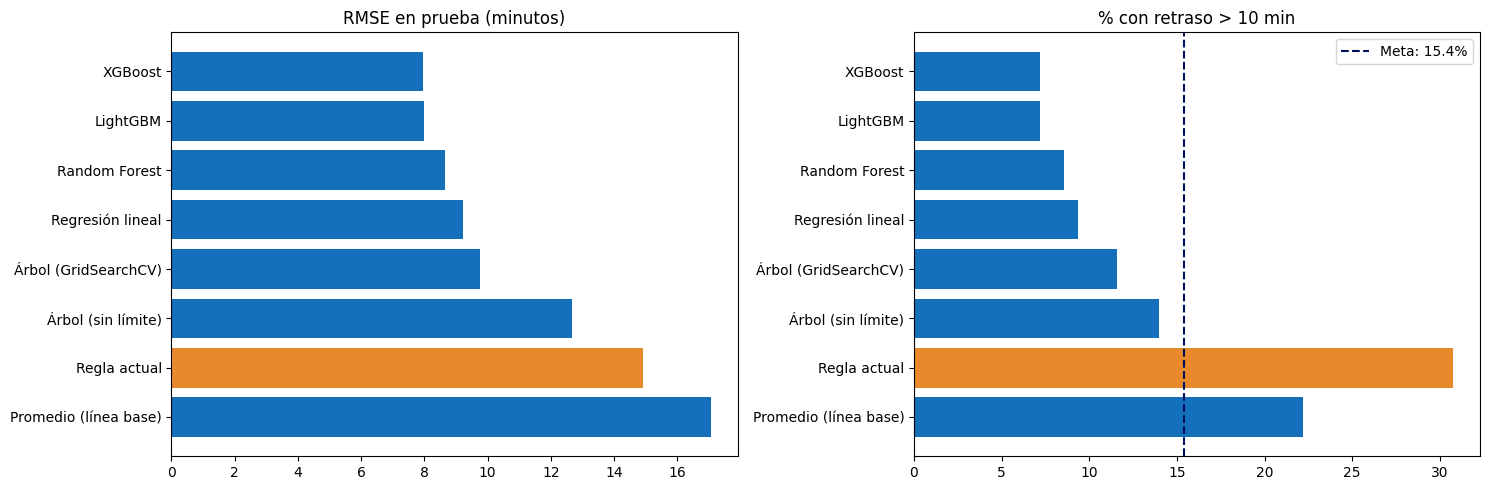

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
orden = tabla.sort_values("RMSE").index
colores = [NARANJA if n == "Regla actual" else AZUL for n in orden]
axes[0].barh(orden, tabla.loc[orden, "RMSE"], color=colores)
axes[0].invert_yaxis()
axes[0].set_title("RMSE en prueba (minutos)")
axes[1].barh(orden, tabla.loc[orden, IND], color=colores)
axes[1].invert_yaxis()
axes[1].axvline(META, color=MARINO, ls="--", label=f"Meta: {META:.1f}%")
axes[1].set_title(IND)
axes[1].legend()
plt.tight_layout()
plt.show()

**Cómo leer este gráfico:** cada barra es un modelo, ordenados de mejor a peor. La barra naranja es la regla actual. A la izquierda, el RMSE: **más corto es mejor**. A la derecha, el % de pedidos con más de 10 min de retraso si se promete lo que estima cada modelo; la línea punteada es la meta del directorio.

Elegimos el modelo con **menor RMSE en prueba**, porque en este negocio los errores grandes son los más costosos: generan cupones y quejas.

In [23]:
candidatos_ml = tabla.drop(index=["Regla actual", "Promedio (línea base)"])
MEJOR = candidatos_ml["RMSE"].idxmin()
mejor_modelo = modelos[MEJOR]
mejor = predicciones[MEJOR]
r = tabla.loc[MEJOR]; base = tabla.loc["Regla actual"]
pd.DataFrame({NOMBRE_LINEA_BASE: base[["MAE", "RMSE", "R²"]], MEJOR: r[["MAE", "RMSE", "R²"]]}).round(2)

,Regla actual,XGBoost
MAE,10.59,5.38
RMSE,14.91,7.94
R²,0.23,0.78


### Entrenamiento vs. prueba: ¿hay sobreajuste?

,R² train,R² test,Diferencia
XGBoost,0.82,0.78,0.04
LightGBM,0.84,0.78,0.06
Random Forest,0.83,0.74,0.08
Regresión lineal,0.69,0.71,-0.01
Árbol (GridSearchCV),0.72,0.67,0.05
Árbol (sin límite),1.00,0.45,0.55


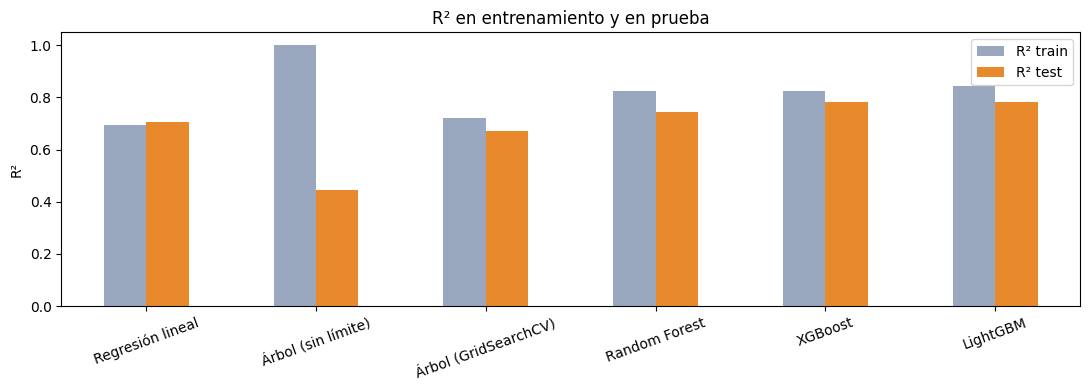

In [25]:
resumen = tabla.drop(index=["Regla actual", "Promedio (línea base)"])[["R² train", "R²"]].rename(columns={"R²": "R² test"})
resumen["Diferencia"] = resumen["R² train"] - resumen["R² test"]
display(resumen.sort_values("R² test", ascending=False))

resumen[["R² train", "R² test"]].plot.bar(figsize=(11, 4), color=[GRIS, NARANJA], rot=20)
plt.ylabel("R²")
plt.title("R² en entrenamiento y en prueba")
plt.tight_layout()
plt.show()

**Cómo leer este gráfico:** para cada modelo, la barra gris es el R² en los datos con los que aprendió y la naranja, en datos nuevos. Si la gris es mucho más alta que la naranja, el modelo **memorizó** en lugar de aprender: eso es sobreajuste.

**Respuesta:** los modelos de *boosting* (XGBoost y LightGBM) son los mejores en todas las métricas. El árbol sin límite memoriza los datos de entrenamiento (R² ≈ 1) y es el peor en prueba: es **sobreajuste**. GridSearchCV corrige ese problema eligiendo una profundidad adecuada. Las métricas que importan son siempre las de **prueba**.

### Importancia de variables

¿Qué variables usa más el modelo para predecir? Comparamos la importancia en Random Forest y en el mejor modelo.

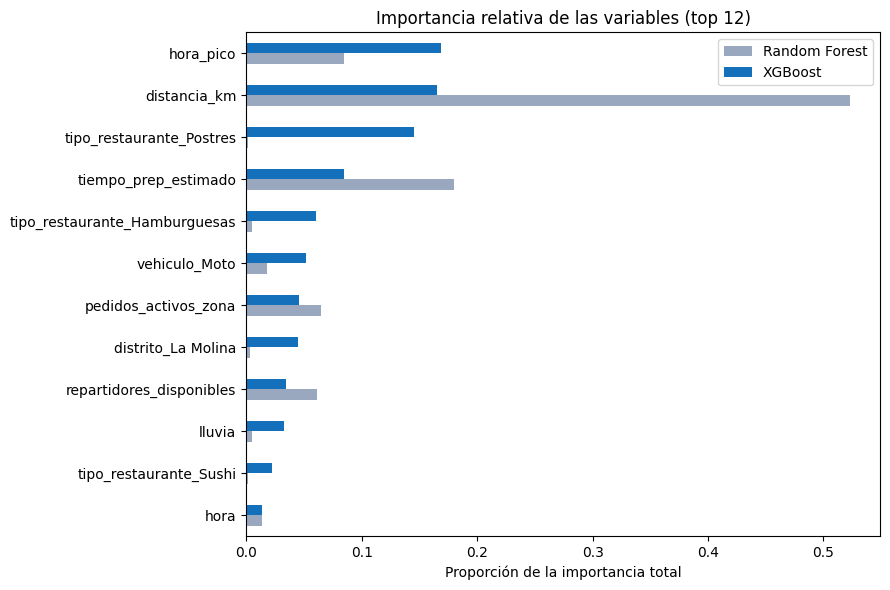

In [26]:
def importancia(modelo):
    if isinstance(modelo, lgb.LGBMRegressor):
        valores = modelo.booster_.feature_importance(importance_type="gain")
    else:
        valores = modelo.feature_importances_
    s = pd.Series(valores, index=X.columns)
    return s / s.sum()

comparacion = pd.DataFrame({"Random Forest": importancia(modelos["Random Forest"]),
                            MEJOR: importancia(mejor_modelo)})
top = comparacion.sort_values(MEJOR).tail(12)
top.plot.barh(figsize=(9, 6), color=[GRIS, AZUL])
plt.title("Importancia relativa de las variables (top 12)")
plt.xlabel("Proporción de la importancia total")
plt.tight_layout()
plt.show()

**Cómo leer este gráfico:** mientras más larga la barra, más usa el modelo esa variable para estimar el tiempo de entrega.

**Respuesta a la pregunta 3:** además de la distancia, pesan el tiempo de preparación, la hora pico, la demanda en la zona, la lluvia y el tipo de restaurante. Ninguna de estas variables está en la regla actual.

## 9. Pregunta 5 · ¿En qué situaciones se equivoca más el modelo?

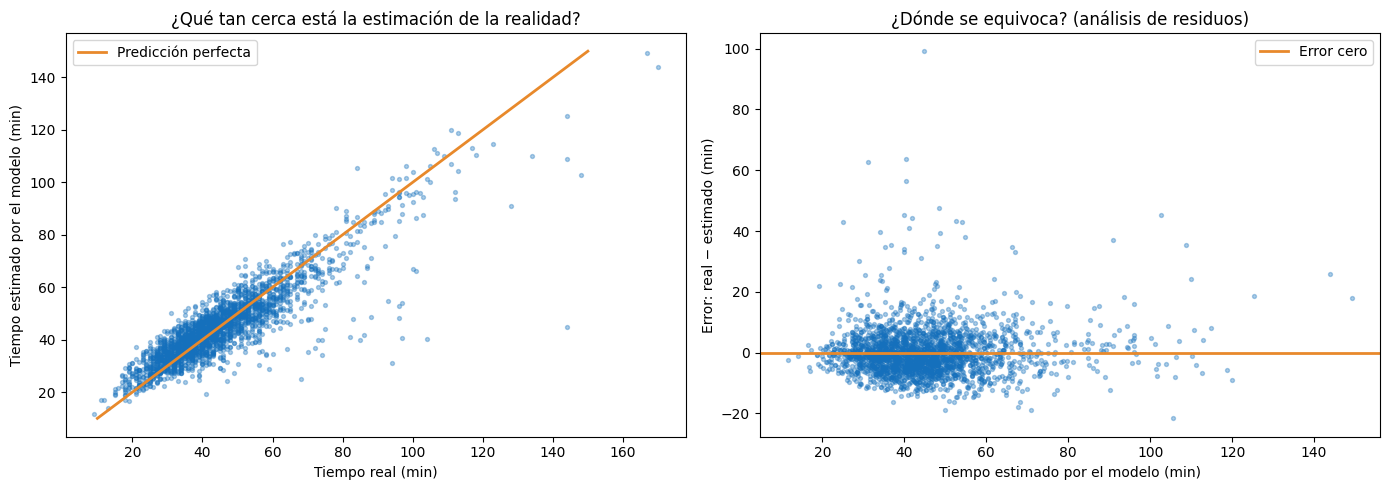

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(y_test, mejor, s=8, alpha=0.35, color=AZUL)
axes[0].plot([10, 150], [10, 150], color=NARANJA, lw=2, label="Predicción perfecta")
axes[0].set_xlabel("Tiempo real (min)")
axes[0].set_ylabel("Tiempo estimado por el modelo (min)")
axes[0].set_title("¿Qué tan cerca está la estimación de la realidad?")
axes[0].legend()
axes[1].scatter(mejor, y_test - mejor, s=8, alpha=0.35, color=AZUL)
axes[1].axhline(0, color=NARANJA, lw=2, label="Error cero")
axes[1].set_xlabel("Tiempo estimado por el modelo (min)")
axes[1].set_ylabel("Error: real − estimado (min)")
axes[1].set_title("¿Dónde se equivoca? (análisis de residuos)")
axes[1].legend()
plt.tight_layout()
plt.show()

**Cómo leer estos gráficos:**

- **Izquierda:** cada punto es un pedido. Si el modelo acertara siempre, todos los puntos estarían sobre la línea naranja. Mientras más cerca de la línea, mejor.
- **Derecha:** muestra el error de cada pedido. Los puntos **por encima de cero** llegaron más tarde de lo estimado; los de **abajo**, antes. Lo deseable es una nube pareja alrededor de cero, sin formas ni embudos.

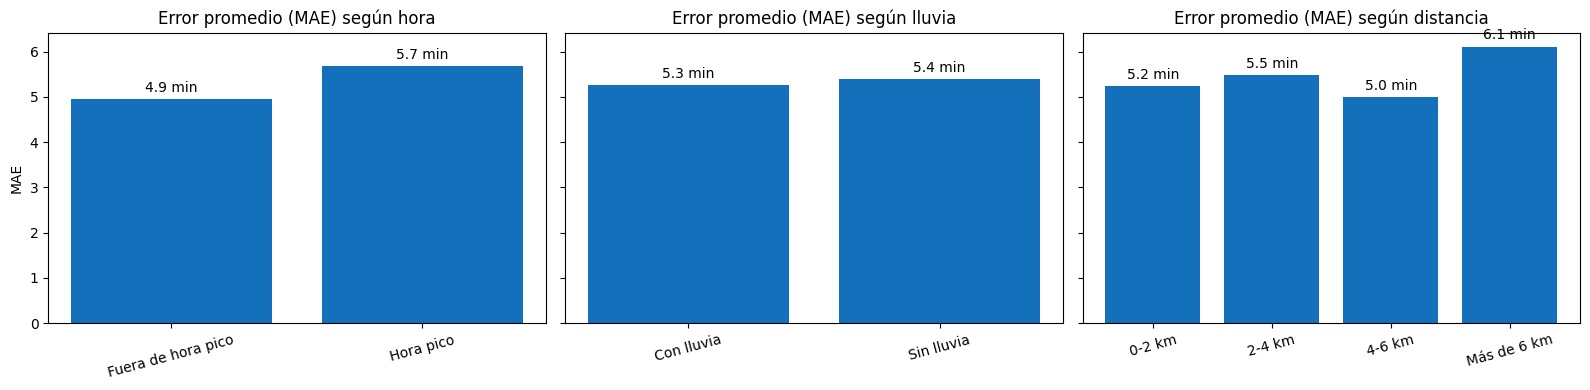

In [28]:
segmentos = X_test.assign(error_abs=np.abs(y_test - mejor))
segmentos["Hora"] = np.where(segmentos["hora_pico"] == 1, "Hora pico", "Fuera de hora pico")
segmentos["Lluvia"] = np.where(segmentos["lluvia"] == 1, "Con lluvia", "Sin lluvia")
segmentos["Distancia"] = pd.cut(segmentos["distancia_km"], [0, 2, 4, 6, 20],
                                labels=["0-2 km", "2-4 km", "4-6 km", "Más de 6 km"])

fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, col in zip(axes, ["Hora", "Lluvia", "Distancia"]):
    mae_seg = segmentos.groupby(col, observed=True)["error_abs"].mean()
    barras = ax.bar(mae_seg.index.astype(str), mae_seg.values, color=AZUL)
    ax.bar_label(barras, fmt="%.1f min", padding=3)
    ax.set_title(f"Error promedio (MAE) según {col.lower()}")
    ax.tick_params(axis="x", rotation=15)
axes[0].set_ylabel("MAE")
plt.tight_layout()
plt.show()

**Respuesta:** la mayoría de errores está cerca de cero, pero hay pedidos muy por encima: retrasos por incidentes que ningún modelo puede anticipar con estos datos. El error es mayor en **hora pico** y en **distancias largas**, donde la operación es más incierta.

## 10. Pregunta 6 · ¿Qué tiempo debe prometer la app?

La respuesta corta: **la estimación del modelo**. La razón está en el error: si el modelo se equivoca menos, la promesa se parece más a la realidad y llegan menos pedidos tarde.

### 10.1 ¿Para qué sirve el modelo?

> **Al replicar:** cambia los dos ejemplos por dos casos de tu negocio que la línea base trate igual, pero que en la realidad sean distintos.

La regla solo mira la distancia: a dos pedidos a 4 km les promete lo mismo. El modelo usa todas las variables. Para usarlo, primero lo reentrenamos con **todos** los datos.

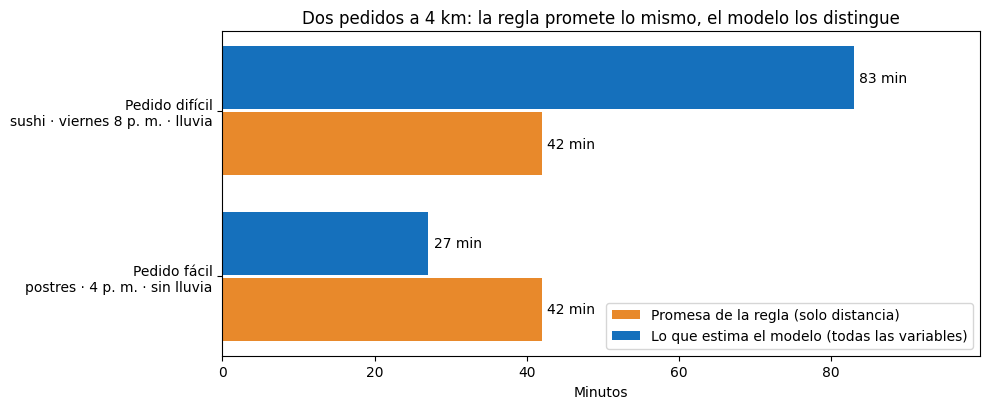

In [30]:
modelo_final = modelos[MEJOR].__class__(**modelos[MEJOR].get_params())
modelo_final.fit(X, y)

def tiempo_estimado(caso):
    # Aplica la misma preparación que a los datos de entrenamiento (sirve para cualquier caso)
    nuevo = crear_variables(pd.DataFrame([caso]))
    nuevo = nuevo.drop(columns=COLUMNAS_A_EXCLUIR, errors="ignore")
    nuevo = pd.get_dummies(nuevo, columns=CATEGORICAS, dtype=int).reindex(columns=X.columns, fill_value=0)
    return float(modelo_final.predict(nuevo)[0])

pedido_dificil = dict(fecha_hora="2025-10-03 20:15", dia_semana="Viernes", hora=20, distrito="Surco",
                      tipo_restaurante="Sushi", calificacion_restaurante=4.5, n_productos=4, tiempo_prep_estimado=28,
                      distancia_km=4.0, vehiculo="Moto", lluvia=1, repartidores_disponibles=3, pedidos_activos_zona=25)
pedido_facil = {**pedido_dificil, "hora": 16, "tipo_restaurante": "Postres", "n_productos": 1, "tiempo_prep_estimado": 10,
                "lluvia": 0, "repartidores_disponibles": 10, "pedidos_activos_zona": 8}

ejemplos = {"Pedido difícil\nsushi · viernes 8 p. m. · lluvia": pedido_dificil,
            "Pedido fácil\npostres · 4 p. m. · sin lluvia": pedido_facil}
promesa_regla = 30 + 3 * 4.0
estimaciones = {nombre: tiempo_estimado(p) for nombre, p in ejemplos.items()}

fig, ax = plt.subplots(figsize=(10, 4.2))
posiciones = np.arange(len(ejemplos))
b1 = ax.barh(posiciones + 0.2, [promesa_regla] * len(ejemplos), height=0.38, color=NARANJA, label="Promesa de la regla (solo distancia)")
b2 = ax.barh(posiciones - 0.2, list(estimaciones.values()), height=0.38, color=AZUL, label="Lo que estima el modelo (todas las variables)")
ax.bar_label(b1, fmt="%.0f min", padding=4)
ax.bar_label(b2, fmt="%.0f min", padding=4)
ax.set_yticks(posiciones, list(estimaciones.keys()))
ax.invert_yaxis()
ax.set_xlabel("Minutos")
ax.set_xlim(0, max(estimaciones.values()) * 1.2)
ax.set_title("Dos pedidos a 4 km: la regla promete lo mismo, el modelo los distingue")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Cómo leer este gráfico:** la barra naranja es lo que promete la regla; la azul, lo que el modelo estima que tardará.

- **Pedido difícil:** la regla promete 42 min, pero tardará mucho más. Llegará tarde y generará un cupón (el problema de **Experiencia del Cliente**).
- **Pedido fácil:** la regla promete 42 min, pero llegará mucho antes. Una promesa tan larga puede espantar al cliente (el problema de **Comercial**).

La regla se equivoca **en los dos sentidos**. El modelo da a cada pedido su propia promesa.

### 10.2 El error del modelo es el retraso del pedido

Si la app promete lo que estima el modelo, el **error del modelo** (real − estimado) es exactamente el **retraso del pedido**. Un error de +12 min significa que el pedido llegó 12 minutos después de lo prometido.

Por eso, reducir el error reduce los pedidos que llegan más de 10 minutos tarde, que son los que generan cupones.

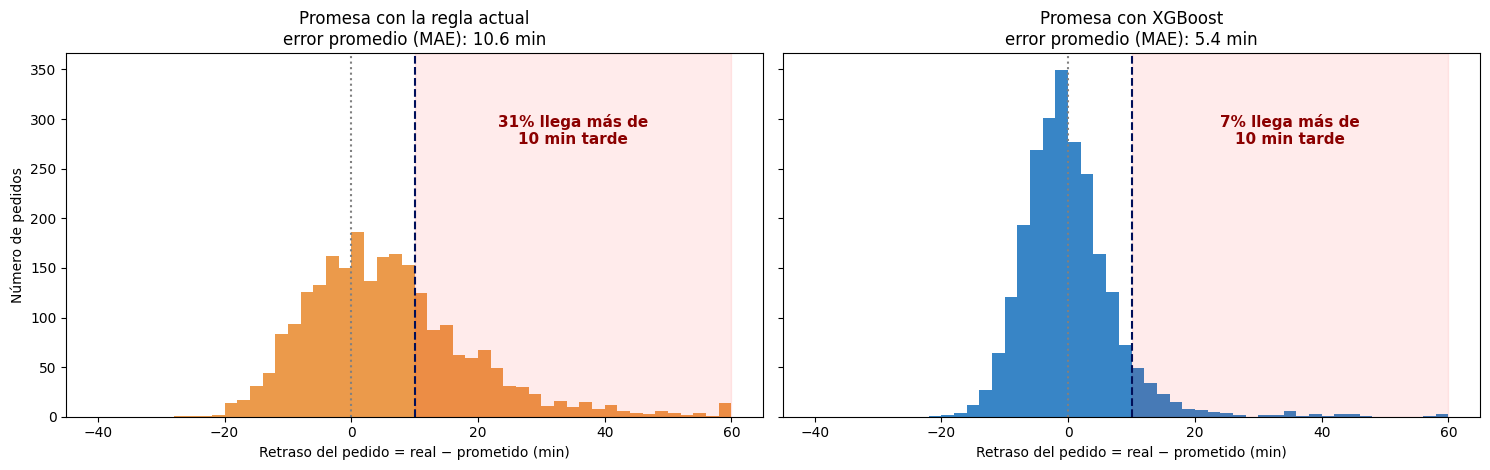

In [31]:
error_base = y_test - pred_regla
error_modelo = y_test - mejor

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), sharey=True)
bins = np.arange(-40, 62, 2)
paneles = [(f"Promesa con la {NOMBRE_LINEA_BASE.lower()}", error_base, NARANJA),
           (f"Promesa con {MEJOR}", error_modelo, AZUL)]
for ax, (titulo, err, color) in zip(axes, paneles):
    ax.hist(err.clip(-40, 60), bins=bins, color=color, alpha=0.85)
    ax.axvspan(TOLERANCIA, 60, color="red", alpha=0.08)
    ax.axvline(0, color="gray", ls=":")
    ax.axvline(TOLERANCIA, color=MARINO, ls="--")
    ax.set_title(f"{titulo}\nerror promedio (MAE): {err.abs().mean():.1f} {UNIDAD}")
    ax.set_xlabel(f"Retraso del pedido = real − prometido ({UNIDAD})")
axes[0].set_ylabel("Número de pedidos")
alto = axes[0].get_ylim()[1]
for ax, err in zip(axes, [error_base, error_modelo]):
    ax.text(35, alto * 0.75, f"{(err > TOLERANCIA).mean() * 100:.0f}% llega más de\n{TOLERANCIA} {UNIDAD} tarde",
            ha="center", color="darkred", fontsize=11, fontweight="bold")
plt.tight_layout()
plt.show()

**Cómo leer este gráfico:** cada barra cuenta cuántos pedidos tuvieron cierto retraso. A la izquierda de 0, el pedido llegó antes de lo prometido; en la zona sombreada, llegó más de 10 minutos tarde y genera cupón.

Con la regla, los errores están muy dispersos y muchos pedidos caen en la zona de cupón. Con el modelo, el error se concentra cerca de cero.

### 10.3 ¿Cumple la meta del directorio?

In [32]:
pct_base = (error_base > TOLERANCIA).mean() * 100
pct_modelo = (error_modelo > TOLERANCIA).mean() * 100
resumen_decision = pd.DataFrame({
    "Error promedio (MAE)": [f"{error_base.abs().mean():.1f} {UNIDAD}", f"{error_modelo.abs().mean():.1f} {UNIDAD}"],
    IND: [f"{pct_base:.0f}%", f"{pct_modelo:.0f}%"],
    f"Meta (≤ {META:.0f}%)": ["Cumple" if p <= META else "No cumple" for p in (pct_base, pct_modelo)],
    "Promesa promedio": [f"{pred_regla.mean():.0f} {UNIDAD}", f"{mejor.mean():.0f} {UNIDAD}"],
    "Pedidos con promesa más corta que hoy": ["—", f"{(mejor < pred_regla).mean() * 100:.0f}%"],
}, index=[NOMBRE_LINEA_BASE, MEJOR])
resumen_decision

,Error promedio (MAE),% con retraso > 10 min,Meta (≤ 15%),Promesa promedio,Pedidos con promesa más corta que hoy
Regla actual,10.6 min,31%,No cumple,39 min,—
XGBoost,5.4 min,7%,Cumple,45 min,31%


### 10.4 ¿Cuánto se ahorra?

Cada pedido que llega más de 10 minutos tarde genera un cupón de S/ 6. Con unos 4,000 pedidos al mes:

$$\text{Costo mensual} = \text{pedidos al mes} \times \%\ \text{con retraso} > 10\ \text{min} \times \text{S/ }6$$

In [33]:
casos_base = round(CASOS_POR_MES * pct_base / 100)
casos_modelo = round(CASOS_POR_MES * pct_modelo / 100)
ahorro_mes = (casos_base - casos_modelo) * COSTO_POR_CASO

ahorro = pd.DataFrame({
    f"{NOMBRE_COSTO.capitalize()} al mes": [f"{CASOS_POR_MES:,} × {pct_base:.1f}% = {casos_base:,.0f}",
                                            f"{CASOS_POR_MES:,} × {pct_modelo:.1f}% = {casos_modelo:,.0f}"],
    "Costo al mes": [f"{casos_base:,.0f} × S/ {COSTO_POR_CASO:.0f} = S/ {casos_base * COSTO_POR_CASO:,.0f}",
                     f"{casos_modelo:,.0f} × S/ {COSTO_POR_CASO:.0f} = S/ {casos_modelo * COSTO_POR_CASO:,.0f}"],
}, index=[NOMBRE_LINEA_BASE, MEJOR])
display(ahorro)
print(f"Ahorro: S/ {ahorro_mes:,.0f} al mes, unos S/ {ahorro_mes * 12:,.0f} al año.")

,Cupones al mes,Costo al mes
Regla actual,"4,000 × 30.8% = 1,230","1,230 × S/ 6 = S/ 7,380"
XGBoost,"4,000 × 7.2% = 288","288 × S/ 6 = S/ 1,728"


Ahorro: S/ 5,652 al mes, unos S/ 67,824 al año.


**Respuesta para cada gerencia:**

- **Experiencia del Cliente:** los pedidos que llegan más de 10 minutos tarde bajan de 1 de cada 3 a menos de 1 de cada 10. Se cumple la meta del directorio y se ahorra en cupones.
- **Comercial:** la promesa promedio sube unos minutos, pero no para todos. El modelo alarga la promesa solo en los pedidos que de verdad tardarán (hora pico, lluvia, sushi) y la **acorta** en los rápidos.

Ninguna gerencia tenía toda la razón: no hay que acortar ni alargar todas las promesas, sino **personalizarlas** con un modelo que se equivoque poco.

## 11. Respuestas para el comité

In [34]:
r = tabla.loc[MEJOR]; base = tabla.loc[NOMBRE_LINEA_BASE]
print("1. QUÉ PREDECIR: el tiempo de entrega de cada pedido (regresión), para dar promesas distintas según el pedido.")
print(f"2. REGLA ACTUAL: se equivoca {base['MAE']:.1f} {UNIDAD} en promedio; el {pct_base:.0f}% llega con más de {TOLERANCIA} {UNIDAD} de retraso.")
print("3. FACTORES: además de la distancia, preparación, hora pico, demanda en la zona, lluvia y tipo de restaurante.")
print(f"4. MEJOR MODELO: {MEJOR}. Se equivoca {r['MAE']:.1f} {UNIDAD} en promedio (R² {r['R²']:.2f}).")
print("5. DÓNDE FALLA: hora pico y distancias largas; los incidentes no son predecibles con estos datos.")
print(f"6. QUÉ PROMETER: la estimación del modelo. Los pedidos con más de {TOLERANCIA} {UNIDAD} de retraso bajan "
      f"de {pct_base:.0f}% a {pct_modelo:.0f}% (meta: {META:.0f}%).")
print(f"7. AHORRO: S/ {ahorro_mes:,.0f} al mes en {NOMBRE_COSTO}, unos S/ {ahorro_mes * 12:,.0f} al año.")

1. QUÉ PREDECIR: el tiempo de entrega de cada pedido (regresión), para dar promesas distintas según el pedido.
2. REGLA ACTUAL: se equivoca 10.6 min en promedio; el 31% llega con más de 10 min de retraso.
3. FACTORES: además de la distancia, preparación, hora pico, demanda en la zona, lluvia y tipo de restaurante.
4. MEJOR MODELO: XGBoost. Se equivoca 5.4 min en promedio (R² 0.78).
5. DÓNDE FALLA: hora pico y distancias largas; los incidentes no son predecibles con estos datos.
6. QUÉ PROMETER: la estimación del modelo. Los pedidos con más de 10 min de retraso bajan de 31% a 7% (meta: 15%).
7. AHORRO: S/ 5,652 al mes en cupones, unos S/ 67,824 al año.


## Cómo replicar este análisis en otro caso

| Parte | Secciones | Qué hacer |
|---|---|---|
| Parámetros del caso | 1 | Modificar la celda de parámetros: datos, variable objetivo, variables derivadas, línea base, tolerancia, meta y costo por caso |
| Exploración | 4 | Adaptar los gráficos a las variables del nuevo caso |
| Ejemplos ilustrativos | 10.1 | Opcional: reemplazar los dos casos de ejemplo |
| Resto del análisis | 2, 3, 5 a 9, 10.2 a 10.4 y 11 | Sin cambios |

La idea central se repite en cualquier problema de regresión: **el error del modelo se traduce en un indicador del negocio**. En RapiMenú, el error es el retraso del pedido; en demanda, son las unidades que faltan o sobran; en crédito, la diferencia entre el monto aprobado y el adecuado.

## 12. Entregable

Prepara una recomendación para el comité (máximo una página o tres diapositivas) que responda:

1. ¿Cuánto mejora el modelo frente a la regla actual? Usa al menos dos métricas y explica qué significan en minutos.
2. ¿Qué modelo recomiendas y por qué? Considera también el sobreajuste.
3. ¿En qué situaciones la predicción es menos confiable y qué harías al respecto?
4. ¿Qué tiempo debería prometer la app para cumplir la meta del directorio? ¿Qué le dirías a Comercial y a Experiencia del Cliente?